<a href="https://colab.research.google.com/github/SKS-Syndicate-A26-CS259/Gen-Ai/blob/main/04_Guardrails_OutOfContext_and_API_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 - Guardrails, Out-of-Context, & FastAPI Endpoint Testing
## **Proyek:** Asah 2026 Capstone — Tim A26-CS259 (SKS Syndicate)
## **PIC:** Mukhamad Fariz Mubarok (`AE009B6Y1293`)
**Mitra UMKM:** UMKM Tujuan Semata (Depok, Jawa Barat)

## **Instalasi Library di Google Colab**

In [2]:
!pip install -q fastapi httpx pydantic pandas chromadb sentence-transformers google-genai matplotlib

## **1. Setup API Key, Path Colab, & Load Dataset**

In [3]:
import os
import time
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import chromadb
from chromadb.utils import embedding_functions
from getpass import getpass
from google import genai
from fastapi import FastAPI
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field

In [5]:
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = os.getenv("GEMINI_API_KEY") or getpass("Masukkan GEMINI_API_KEY: ")

gemini_client = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

MENU_PATH = "/content/katalog_menu_tujuan_semata.csv"
TESTSET_PATH = "/content/rag_golden_testset_50.csv"
CHROMA_DIR = "/content/vectorstore/chroma_menu_db"
REPORT_DIR = "/content/reports"
os.makedirs(REPORT_DIR, exist_ok=True)

df_menu = pd.read_csv(MENU_PATH)
df_test_all = pd.read_csv(TESTSET_PATH)

In [6]:
# Ambil 30 pertanyaan relevan + 10 out-of-context sesuai target Project Plan
df_rel_30 = df_test_all[df_test_all["kategori_uji"] == "relevan"].head(30)
df_ooc_10 = df_test_all[df_test_all["kategori_uji"] == "out_of_context"].head(10)
df_test_40 = pd.concat([df_rel_30, df_ooc_10], ignore_index=True)

print(f"API Key Siap : {gemini_client is not None}")
print(f"Katalog Menu : {len(df_menu)} baris")
print(f"Uji Guardrail: {len(df_test_40)} skenario ({df_test_40['kategori_uji'].value_counts().to_dict()})")

API Key Siap : True
Katalog Menu : 120 baris
Uji Guardrail: 40 skenario ({'relevan': 30, 'out_of_context': 10})


## **2. Load atau Bangun ChromaDB Vectorstore (120 Menu + Profil Warung)**

In [7]:
embed_fn = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

def to_bool(val) -> bool:
    return str(val).strip().lower() in ["true", "1", "ya"]

if not os.path.exists(os.path.join(CHROMA_DIR, "chroma.sqlite3")):
    os.makedirs(CHROMA_DIR, exist_ok=True)
    chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)
    collection = chroma_client.get_or_create_collection(
        name="tujuan_semata_menu",
        embedding_function=embed_fn,
        metadata={"hnsw:space": "cosine"},
    )
    docs, metas, ids = [], [], []
    for _, row in df_menu.iterrows():
        catatan = str(row["Catatan_Khusus_Owner"]) if pd.notna(row["Catatan_Khusus_Owner"]) else "-"
        docs.append(
            f"Menu: {row['Nama_Menu']} ({row['Kode_Menu']}). Kategori: {row['Kategori_Menu']} - {row['Sub_Kategori']}. "
            f"Harga: Rp{int(row['Harga_Jual']):,} ({row['Varian_Harga_Teks']}). Bahan: {row['Komposisi_Bahan']}. "
            f"Rasa: {row['Karakter_Rasa']}. Menu Baru: {'Ya' if to_bool(row['Badge_Menu_Baru']) else 'Tidak'}. "
            f"Terlaris: {'Ya' if to_bool(row['Indikasi_Terlaris']) else 'Tidak'}. "
            f"Esens Rum Non-Alkohol: {'Ya' if to_bool(row['Mengandung_Esens_Rum']) else 'Tidak'}. "
            f"Ramah Anak: {'Ya' if to_bool(row['Ramah_Anak']) else 'Tidak'}. Catatan Owner: {catatan}."
        )
        metas.append({"nama_menu": str(row["Nama_Menu"]), "harga_jual": int(row["Harga_Jual"])})
        ids.append(str(row["Kode_Menu"]))

    docs.extend([
        "Profil UMKM Tujuan Semata: Kedai F&B di Depok, Jawa Barat (dikelola Ibu Shinta sejak 2022) dengan 120 varian menu.",
        "Alur Pesan & Bayar: Pilih menu di web lalu tunjukkan Ringkasan Pilihan Menu ke kasir. Pembayaran dilakukan langsung di kasir (belum mendukung QRIS/VA online).",
    ])
    metas.extend([
        {"nama_menu": "Profil Warung", "harga_jual": 0},
        {"nama_menu": "Alur Pesan & Bayar", "harga_jual": 0},
    ])
    ids.extend(["INFO-WARUNG-01", "INFO-WARUNG-02"])
    collection.add(ids=ids, documents=docs, metadatas=metas)
else:
    chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)
    collection = chroma_client.get_collection(name="tujuan_semata_menu", embedding_function=embed_fn)

print(f"ChromaDB aktif dengan {collection.count()} dokumen.")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

ChromaDB aktif dengan 122 dokumen.


## **3. Definisi Endpoint FastAPI `POST /ai/v1/chat` + Guardrails + Fallback HTTP 429**

In [9]:
SYSTEM_PROMPT = """Kamu adalah Asisten Menu resmi UMKM Tujuan Semata (Depok, Jawa Barat).
ATURAN KETAT:
1. Jawab HANYA berdasarkan KONTEKS MENU yang diberikan. Jangan mengarang menu atau harga.
2. Jika ditanya data rahasia (HPP, modal, omzet, nomor HP member) atau topik di luar UMKM Tujuan Semata, TOLAK DENGAN SOPAN.
3. Jika ditanya kopi dengan rum, jelaskan tegas bahwa yang digunakan adalah esens rum non-alkohol.
4. Jawab ringkas, ramah, dan jelas dalam Bahasa Indonesia."""

OOC_PATTERNS = [
    "hpp", "modal", "omzet", "untung", "profit", "nomor hp", "data member",
    "presiden", "pemilu", "python", "scraping", "coding", "saham", "starbucks",
    "integral", "bola", "obat", "jepang", "meretas", "hotel", "ojek online", "avengers"
]

POLITE_REFUSAL = (
    "Maaf, saya hanya dapat membantu menjawab pertanyaan seputar menu, harga, "
    "komposisi, dan layanan UMKM Tujuan Semata."
)

app = FastAPI(title="Tujuan Semata Gen-AI API", version="1.0.0")

class ChatRequest(BaseModel):
    message: str = Field(..., min_length=2, max_length=300, description="Pertanyaan pelanggan")
    simulate_429: bool = Field(default=False, description="Flag khusus untuk uji simulasi HTTP 429")

class ChatResponse(BaseModel):
    reply: str
    intent_status: str
    engine_used: str
    latency_s: float

@app.post("/ai/v1/chat", response_model=ChatResponse)
def chat_endpoint(req: ChatRequest):
    start = time.perf_counter()
    query = req.message.strip()

    # 1. Guardrail Out-of-Context & Data Sensitif
    if any(p in query.lower() for p in OOC_PATTERNS):
        return ChatResponse(
            reply=POLITE_REFUSAL,
            intent_status="blocked_ooc",
            engine_used="guardrail_local",
            latency_s=round(time.perf_counter() - start, 3),
        )

    # 2. Retrieval Top-8 dari ChromaDB
    res = collection.query(query_texts=[query], n_results=8)
    contexts = res["documents"][0] if res and res["documents"] else []
    context_block = "\n".join(f"- {c}" for c in contexts)
    prompt = f"{SYSTEM_PROMPT}\n\nKONTEKS MENU:\n{context_block}\n\nPERTANYAAN: {query}\nJAWABAN:"

    # 3. Primary Gemini API + Auto-Fallback saat HTTP 429 / gangguan API
    try:
        if req.simulate_429:
            raise RuntimeError("429 RESOURCE_EXHAUSTED (Simulasi Rate Limit)")
        if gemini_client is None:
            raise RuntimeError("GEMINI_API_KEY belum diset")

        resp = gemini_client.models.generate_content(
            model="gemini-3.1-flash-lite",
            contents=prompt,
        )
        return ChatResponse(
            reply=resp.text.strip(),
            intent_status="relevant_menu",
            engine_used="gemini-3.1-flash-lite",
            latency_s=round(time.perf_counter() - start, 3),
        )
    except Exception:
        fallback_reply = (
            "Maaf, layanan asisten cerdas sedang padat. Berdasarkan katalog UMKM Tujuan Semata, "
            "berikut info menu paling relevan:\n" + "\n".join(contexts[:2])
        )
        return ChatResponse(
            reply=fallback_reply,
            intent_status="relevant_menu",
            engine_used="fallback_chromadb",
            latency_s=round(time.perf_counter() - start, 3),
        )

client = TestClient(app)
print("FastAPI TestClient siap diuji.")

FastAPI TestClient siap diuji.


## **4. Jalankan 4 Suite Pengujian (30 Katalog + 10 OOC + 5 Simulasi 429 + 4 Input Invalid)**

In [10]:
def check_keyword_pass(answer: str, expected_keywords: str, kategori: str) -> bool:
    ans_low = answer.lower()
    kws = [k.strip().lower() for k in str(expected_keywords).split("|") if k.strip()]
    matched = any(k in ans_low for k in kws)
    if kategori == "out_of_context":
        return ("maaf" in ans_low or "tidak dapat" in ans_low) and matched
    return matched

test_logs = []

### **A & B: 30 Relevan + 10 Out-of-Context**

In [11]:
for idx, row in df_test_40.iterrows():
    r = client.post("/ai/v1/chat", json={"message": row["pertanyaan"]})
    data = r.json()
    ok = (r.status_code == 200) and check_keyword_pass(data["reply"], row["expected_keywords"], row["kategori_uji"])
    suite_name = "1. Katalog Relevan (30)" if row["kategori_uji"] == "relevan" else "2. Guardrail OOC (10)"

    print(f"[{idx+1}/40] {row['id_uji']} | HTTP {r.status_code} | {data['engine_used']} | Pass: {ok} ({data['latency_s']}s)")
    test_logs.append({
        "test_suite": suite_name,
        "id_uji": row["id_uji"],
        "pertanyaan": row["pertanyaan"],
        "http_status": r.status_code,
        "engine_used": data["engine_used"],
        "latency_s": data["latency_s"],
        "passed": ok,
        "reply_snippet": data["reply"][:140],
    })
    if data["engine_used"] == "gemini-3.1-flash-lite":
        time.sleep(4.5)

[1/40] GT-01 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (2.84s)
[2/40] GT-02 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (2.191s)
[3/40] GT-03 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.733s)
[4/40] GT-04 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.927s)
[5/40] GT-05 | HTTP 200 | fallback_chromadb | Pass: True (5.19s)
[6/40] GT-06 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.415s)
[7/40] GT-07 | HTTP 200 | gemini-3.1-flash-lite | Pass: False (1.764s)
[8/40] GT-08 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (5.791s)
[9/40] GT-09 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.36s)
[10/40] GT-10 | HTTP 200 | fallback_chromadb | Pass: True (55.361s)
[11/40] GT-11 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.196s)
[12/40] GT-12 | HTTP 200 | fallback_chromadb | Pass: False (4.194s)
[13/40] GT-13 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (34.826s)
[14/40] GT-14 | HTTP 200 | gemini-3.1-flash-lite | Pass: True (1.541s)
[15/40] GT-15 | HTTP 200 |

### **C: 5 Simulasi HTTP 429**

In [12]:
for i, row in df_rel_30.head(5).iterrows():
    r = client.post("/ai/v1/chat", json={"message": row["pertanyaan"], "simulate_429": True})
    data = r.json()
    ok = (r.status_code == 200) and (data["engine_used"] == "fallback_chromadb") and len(data["reply"]) > 20
    test_logs.append({
        "test_suite": "3. Fallback HTTP 429 (5)",
        "id_uji": f"FB-{len(test_logs)+1}",
        "pertanyaan": row["pertanyaan"],
        "http_status": r.status_code,
        "engine_used": data["engine_used"],
        "latency_s": data["latency_s"],
        "passed": ok,
        "reply_snippet": data["reply"][:140],
    })

### **D: 4 Uji Validasi Input Kosong / Terlalu Pendek / Terlalu Panjang**

In [13]:
invalid_payloads = [
    ("INV-01", {"message": ""}),
    ("INV-02", {"message": "a"}),
    ("INV-03", {"message": "x" * 350}),
    ("INV-04", {}),
]
for inv_id, payload in invalid_payloads:
    r = client.post("/ai/v1/chat", json=payload)
    ok = (r.status_code == 422)
    test_logs.append({
        "test_suite": "4. Validasi Input 422 (4)",
        "id_uji": inv_id,
        "pertanyaan": str(payload)[:60],
        "http_status": r.status_code,
        "engine_used": "pydantic_validator",
        "latency_s": 0.0,
        "passed": ok,
        "reply_snippet": str(r.json())[:140],
    })

df_report = pd.DataFrame(test_logs)
report_csv = os.path.join(REPORT_DIR, "guardrails_api_test_report.csv")
df_report.to_csv(report_csv, index=False)

summary = (
    df_report.groupby("test_suite", as_index=False)
    .agg(
        Total_Uji=("passed", "count"),
        Lulus=("passed", "sum"),
        Pass_Rate_Pct=("passed", lambda s: round(s.mean() * 100, 1)),
        Avg_Latency_s=("latency_s", lambda s: round(s.mean(), 3)),
    )
)
display(summary)

,test_suite,Total_Uji,Lulus,Pass_Rate_Pct,Avg_Latency_s
0,1. Katalog Relevan (30),30,25,83.3,6.095
1,2. Guardrail OOC (10),10,10,100.0,0.000
2,3. Fallback HTTP 429 (5),5,5,100.0,0.036
3,4. Validasi Input 422 (4),4,4,100.0,0.000


## **5. Visualisasi Hasil Pengujian Guardrails & API**

### Tingkat Kelulusan per Suite

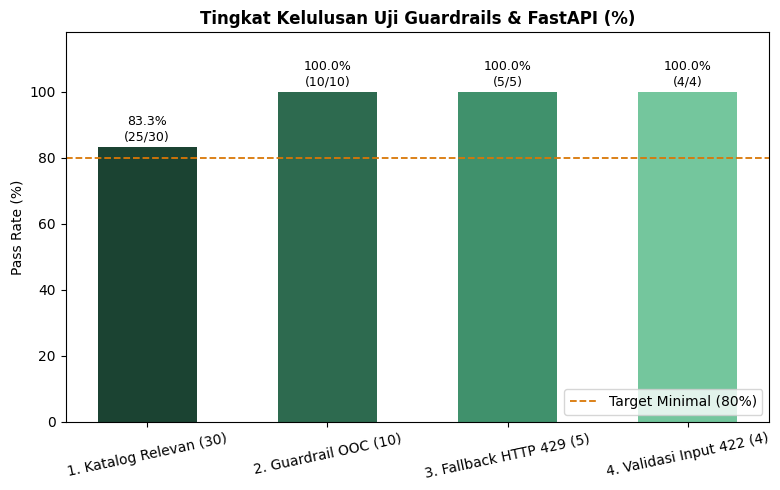

Disimpan: /content/reports/01_guardrails_pass_rate.png


In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    summary["test_suite"],
    summary["Pass_Rate_Pct"],
    color=["#1B4332", "#2D6A4F", "#40916C", "#74C69D"],
    width=0.55,
)
ax.axhline(80, color="#D97706", linestyle="--", linewidth=1.3, label="Target Minimal (80%)")
ax.set_ylim(0, 118)
ax.set_title("Tingkat Kelulusan Uji Guardrails & FastAPI (%)", fontweight="bold")
ax.set_ylabel("Pass Rate (%)")
ax.tick_params(axis="x", rotation=12)
ax.legend(loc="lower right")

for bar, lulus, tot in zip(bars, summary["Lulus"], summary["Total_Uji"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%\n({int(lulus)}/{int(tot)})",
        ha="center",
        fontsize=9,
    )

plt.tight_layout()
p1 = os.path.join(REPORT_DIR, "01_guardrails_pass_rate.png")
plt.savefig(p1, dpi=150)
plt.show()
print("Disimpan:", p1)

### Rata-rata Latensi per Engine

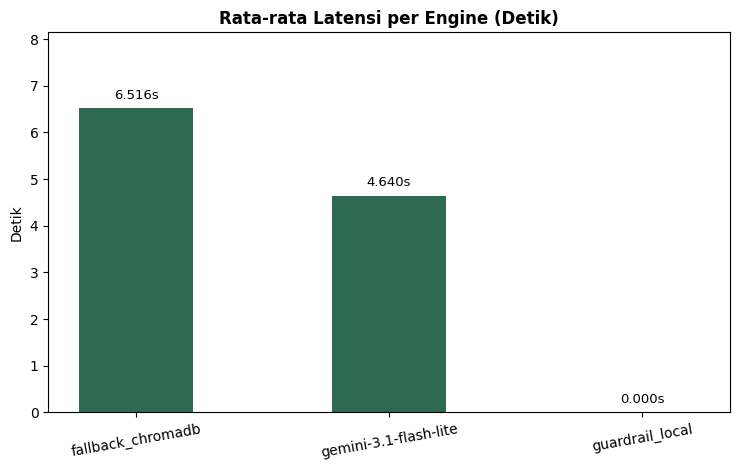

Disimpan: /content/reports/02_engine_latency.png


In [25]:
lat_df = df_report[df_report["engine_used"] != "pydantic_validator"]
lat_sum = lat_df.groupby("engine_used", as_index=False)["latency_s"].mean().sort_values("latency_s", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.bar(lat_sum["engine_used"], lat_sum["latency_s"], color="#2D6A4F", width=0.45)
ax.set_title("Rata-rata Latensi per Engine (Detik)", fontweight="bold")
ax.set_ylabel("Detik")
ax.set_ylim(0, max(lat_sum["latency_s"].max() * 1.25, 0.5))
ax.tick_params(axis="x", rotation=10)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (lat_sum["latency_s"].max() * 0.03 + 0.01),
        f"{bar.get_height():.3f}s",
        ha="center",
        fontsize=9.5,
    )

plt.tight_layout()
p2 = os.path.join(REPORT_DIR, "02_engine_latency.png")
plt.savefig(p2, dpi=150)
plt.show()
print("Disimpan:", p2)

### Jumlah Uji Lulus vs Gagal

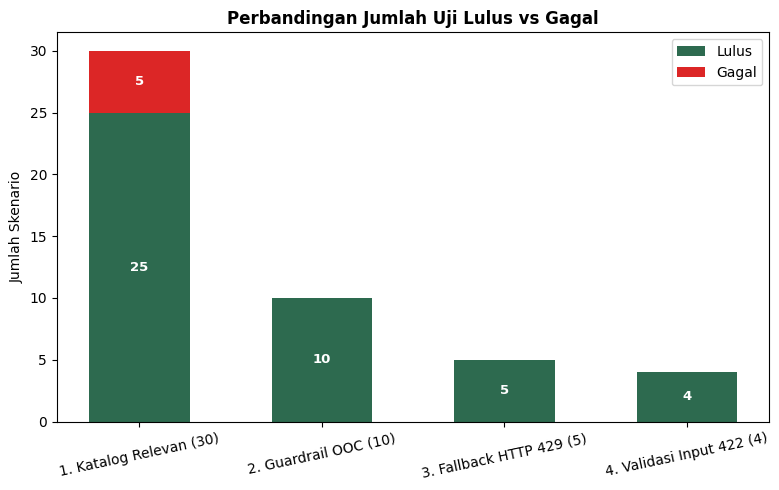

Disimpan: /content/reports/03_lulus_vs_gagal.png


In [26]:
lulus_vals = summary["Lulus"].astype(int)
gagal_vals = summary["Total_Uji"].astype(int) - lulus_vals

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(summary["test_suite"], lulus_vals, label="Lulus", color="#2D6A4F", width=0.55)
ax.bar(summary["test_suite"], gagal_vals, bottom=lulus_vals, label="Gagal", color="#DC2626", width=0.55)
ax.set_title("Perbandingan Jumlah Uji Lulus vs Gagal", fontweight="bold")
ax.set_ylabel("Jumlah Skenario")
ax.tick_params(axis="x", rotation=12)
ax.legend()

for idx_b, (lu, ga) in enumerate(zip(lulus_vals, gagal_vals)):
    if lu > 0:
        ax.text(idx_b, lu / 2, str(lu), ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    if ga > 0:
        ax.text(idx_b, lu + ga / 2, str(ga), ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)

plt.tight_layout()
p3 = os.path.join(REPORT_DIR, "03_lulus_vs_gagal.png")
plt.savefig(p3, dpi=150)
plt.show()
print("Disimpan:", p3)

### Distribusi Engine & Status HTTP

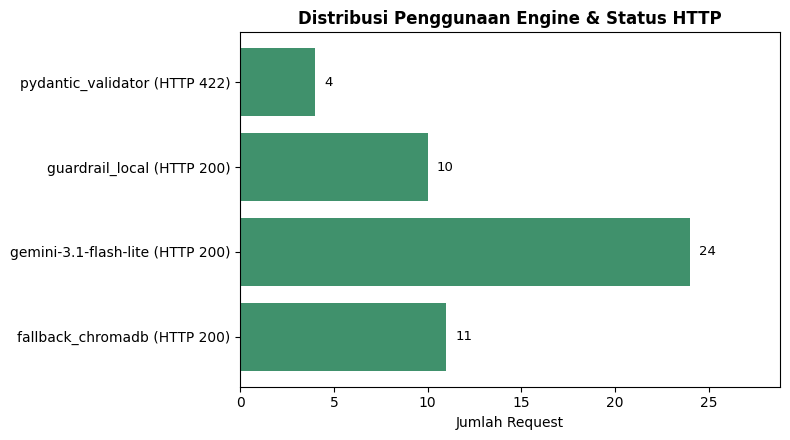

Disimpan: /content/reports/04_distribusi_engine_http.png


In [27]:
eng_counts = df_report.groupby(["engine_used", "http_status"]).size().reset_index(name="jumlah")
labels_eng = [f"{r['engine_used']} (HTTP {r['http_status']})" for _, r in eng_counts.iterrows()]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(labels_eng, eng_counts["jumlah"], color="#40916C")
ax.set_title("Distribusi Penggunaan Engine & Status HTTP", fontweight="bold")
ax.set_xlabel("Jumlah Request")
ax.set_xlim(0, eng_counts["jumlah"].max() * 1.2)

for bar in bars:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        fontsize=9.5,
    )

plt.tight_layout()
p4 = os.path.join(REPORT_DIR, "04_distribusi_engine_http.png")
plt.savefig(p4, dpi=150)
plt.show()
print("Disimpan:", p4)

In [ ]:
from google.colab import files
files.download(report_csv)
files.download(fig_path)